## Etape 1

In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score,mean_absolute_percentage_error)

In [140]:
series = pd.read_csv('pjme-hourly.csv')

In [141]:
series.head()


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [142]:
series.info()

<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  145366 non-null  str    
 1   PJME_MW   145366 non-null  float64
dtypes: float64(1), str(1)
memory usage: 4.9 MB


In [143]:
series['Datetime']=pd.to_datetime(series['Datetime'])
series

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0
...,...,...
145361,2018-01-01 20:00:00,44284.0
145362,2018-01-01 21:00:00,43751.0
145363,2018-01-01 22:00:00,42402.0
145364,2018-01-01 23:00:00,40164.0


In [144]:
series.dtypes

Datetime    datetime64[us]
PJME_MW            float64
dtype: object

In [145]:
series.describe()

,Datetime,PJME_MW
count,145366,145366.000000
mean,2010-04-18 03:25:25.999202,32080.222831
min,2002-01-01 01:00:00,14544.000000
25%,2006-02-23 14:15:00,27573.000000
50%,2010-04-18 04:30:00,31421.000000
75%,2014-06-10 18:45:00,35650.000000
max,2018-08-03 00:00:00,62009.000000
std,NaN,6464.012166


In [146]:
series['PJME_MW'].describe()

count    145366.000000
mean      32080.222831
std        6464.012166
min       14544.000000
25%       27573.000000
50%       31421.000000
75%       35650.000000
max       62009.000000
Name: PJME_MW, dtype: float64

In [147]:
print(series["Datetime"].min(), series["Datetime"].max())
print(series["Datetime"].max() - series["Datetime"].min())

2002-01-01 01:00:00 2018-08-03 00:00:00
6057 days 23:00:00


In [148]:
print(series["Datetime"].is_monotonic_increasing)

False


In [149]:
print(series["Datetime"].sort_values().diff().value_counts().head())

Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
0 days 00:00:00         4
Name: count, dtype: int64


In [150]:
print(series.isna().sum())

Datetime    0
PJME_MW     0
dtype: int64


In [151]:
print(series["Datetime"].duplicated().sum())


4


In [152]:

dates = pd.DatetimeIndex(pd.to_datetime(series["Datetime"])).drop_duplicates().sort_values()


full_range = pd.date_range(dates.min(), dates.max(), freq="h")

missing_ts = full_range.difference(dates)

print("Heures attendues :", len(full_range))
print("Lignes existantes (uniques) :", len(dates))
print("Heures manquantes :", len(missing_ts)) 
print(missing_ts[:5])

Heures attendues : 145392
Lignes existantes (uniques) : 145362
Heures manquantes : 30
DatetimeIndex(['2002-04-07 03:00:00', '2002-10-27 02:00:00',
               '2003-04-06 03:00:00', '2003-10-26 02:00:00',
               '2004-04-04 03:00:00'],
              dtype='datetime64[us]', freq=None)


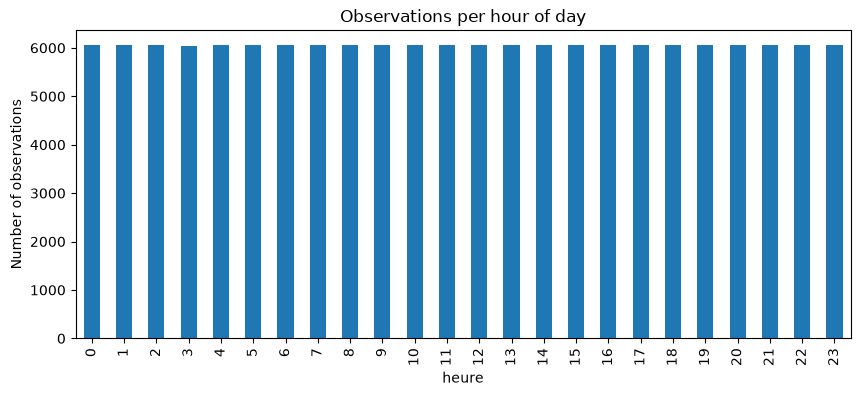

In [153]:
series["Datetime"].dt.hour.value_counts().sort_index().plot(
    kind="bar", figsize=(10, 4), title="Observations per hour of day")
plt.xlabel("heure")
plt.ylabel("Number of observations")
plt.show()

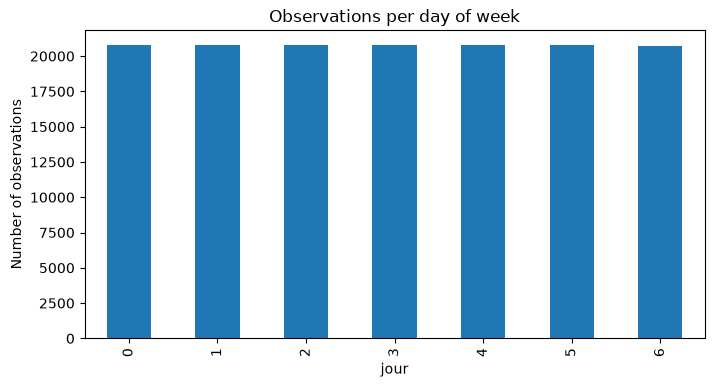

In [154]:
series["Datetime"].dt.dayofweek.value_counts().sort_index().plot(
    kind="bar", figsize=(8, 4), title="Observations per day of week")
plt.xlabel("jour")
plt.ylabel("Number of observations")
plt.show()

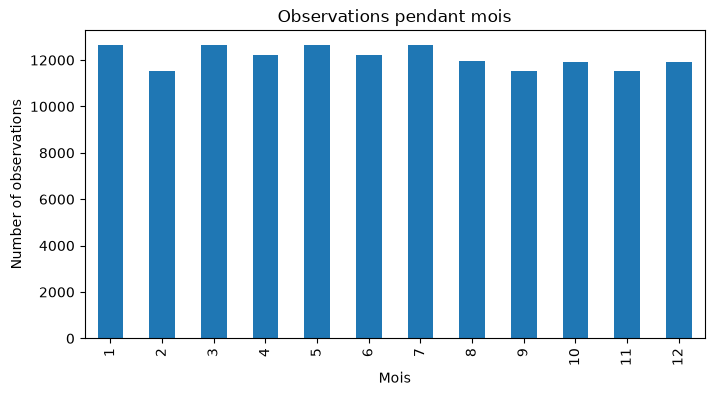

In [155]:
series["Datetime"].dt.month.value_counts().sort_index().plot(
    kind="bar", figsize=(8, 4), title="Observations pendant mois")
plt.xlabel("Mois")
plt.ylabel("Number of observations")
plt.show()

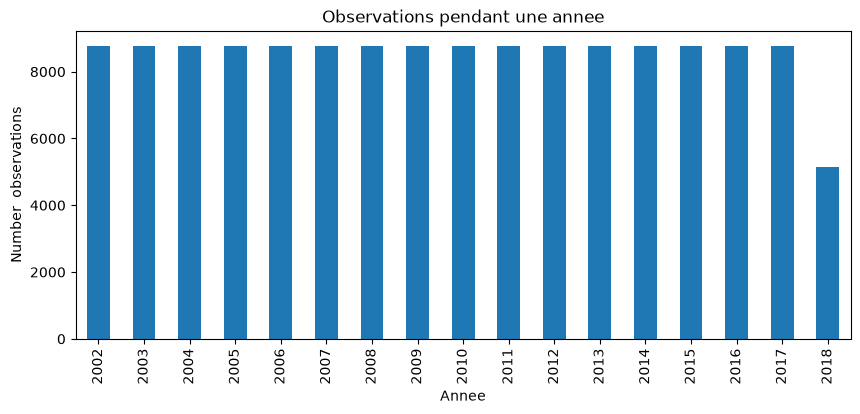

In [156]:
series["Datetime"].dt.year.value_counts().sort_index().plot(
    kind="bar", figsize=(10, 4), title="Observations pendant une annee")
plt.xlabel("Annee")
plt.ylabel("Number  observations")
plt.show()

## Etape 2

In [157]:
print(series.duplicated().sum())
print(series.isna().sum())

0
Datetime    0
PJME_MW     0
dtype: int64


In [158]:
full_range = pd.date_range(series["Datetime"].min(), series["Datetime"].max(), freq="h")
missing_ts = full_range.difference(series["Datetime"])
print(full_range)
print("les heurs manquants:", len(missing_ts))
print(missing_ts)

DatetimeIndex(['2002-01-01 01:00:00', '2002-01-01 02:00:00',
               '2002-01-01 03:00:00', '2002-01-01 04:00:00',
               '2002-01-01 05:00:00', '2002-01-01 06:00:00',
               '2002-01-01 07:00:00', '2002-01-01 08:00:00',
               '2002-01-01 09:00:00', '2002-01-01 10:00:00',
               ...
               '2018-08-02 15:00:00', '2018-08-02 16:00:00',
               '2018-08-02 17:00:00', '2018-08-02 18:00:00',
               '2018-08-02 19:00:00', '2018-08-02 20:00:00',
               '2018-08-02 21:00:00', '2018-08-02 22:00:00',
               '2018-08-02 23:00:00', '2018-08-03 00:00:00'],
              dtype='datetime64[us]', length=145392, freq='h')
les heurs manquants: 30
DatetimeIndex(['2002-04-07 03:00:00', '2002-10-27 02:00:00',
               '2003-04-06 03:00:00', '2003-10-26 02:00:00',
               '2004-04-04 03:00:00', '2004-10-31 02:00:00',
               '2005-04-03 03:00:00', '2005-10-30 02:00:00',
               '2006-04-02 03:00:00', '

## etape

In [159]:
s = series.set_index("Datetime")["PJME_MW"]

#### verifier les valuers negatifs

In [160]:
print(s.describe())
print("Valeurs nulles ou negatives :", (s <= 0).sum())

count    145366.000000
mean      32080.222831
std        6464.012166
min       14544.000000
25%       27573.000000
50%       31421.000000
75%       35650.000000
max       62009.000000
Name: PJME_MW, dtype: float64
Valeurs nulles ou negatives : 0


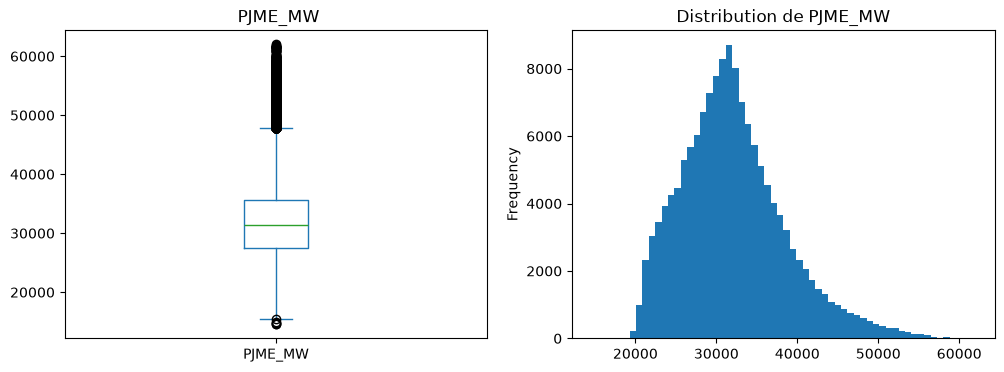

In [161]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
s.plot(kind="box", ax=ax[0], title=" PJME_MW")
s.plot(kind="hist", bins=60, ax=ax[1], title="Distribution de PJME_MW")
plt.show()

In [162]:
z = (s - s.mean()) / s.std()
anomalies_z = s[z.abs() > 3]
print("Anomalies :", len(anomalies_z))

Anomalies : 1318


### Anomalies contextules

In [163]:
groupes = [s.index.month, s.index.hour]
moyenne = s.groupby(groupes).transform("mean")
ecart_type = s.groupby(groupes).transform("std")

z_ctx = (s - moyenne) / ecart_type
anomalies = s[z_ctx.abs() > 3.5]

print("Anomalies contextuelles :", len(anomalies))
print("Les plus basses :")
print(anomalies.sort_values().head(10))
print("Les plus hautes :")
print(anomalies.sort_values().tail(10))

Anomalies contextuelles : 228
Les plus basses :
Datetime
2012-10-30 04:00:00    14544.0
2012-10-30 03:00:00    14586.0
2012-10-30 05:00:00    14821.0
2012-10-30 02:00:00    14955.0
2012-10-30 01:00:00    15390.0
2012-10-30 06:00:00    15526.0
2012-10-30 00:00:00    15919.0
2012-10-29 23:00:00    17422.0
2012-10-30 09:00:00    18675.0
2012-10-29 22:00:00    19085.0
Name: PJME_MW, dtype: float64
Les plus hautes :
Datetime
2011-05-31 15:00:00    51593.0
2012-05-29 16:00:00    51665.0
2012-05-29 17:00:00    51936.0
2011-05-31 18:00:00    52451.0
2011-05-31 16:00:00    52529.0
2006-08-01 23:00:00    52561.0
2006-08-02 23:00:00    52774.0
2011-05-31 17:00:00    53057.0
2006-08-01 22:00:00    56774.0
2006-08-02 22:00:00    56822.0
Name: PJME_MW, dtype: float64


#### sauts entre deux heures

In [164]:
diff = s.diff().abs()
seuil = diff.quantile(0.999)
sauts = diff[diff > seuil]

print("Plus gros sauts horaires :")
print(sauts.sort_values(ascending=False).head(10))

Plus gros sauts horaires :
Datetime
2012-06-19 01:00:00    15998.0
2002-07-28 01:00:00    14285.0
2014-01-06 01:00:00    13689.0
2014-06-16 01:00:00    13493.0
2011-06-07 01:00:00    13416.0
2014-07-06 01:00:00    13137.0
2005-07-25 01:00:00    13026.0
2002-07-27 01:00:00    12984.0
2007-06-25 01:00:00    12417.0
2012-06-20 01:00:00    12398.0
Name: PJME_MW, dtype: float64


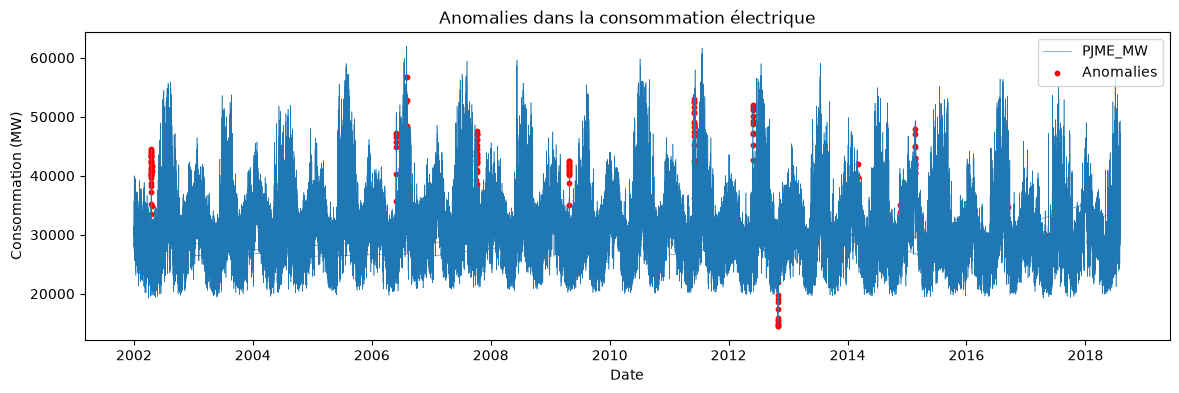

In [165]:
plt.figure(figsize=(14, 4))
plt.plot(s, linewidth=0.4, label="PJME_MW")
plt.scatter(anomalies.index, anomalies.values, color="red", s=10, label="Anomalies")
plt.title("Anomalies dans la consommation électrique")
plt.xlabel("Date")
plt.ylabel("Consommation (MW)")
plt.legend()
plt.show()

### Nettoyage des données


In [ ]:
s = series.groupby("Datetime")["PJME_MW"].mean().sort_index()

s[s <= 0] = float("nan")

full_range = pd.date_range(s.index.min(), s.index.max(), freq="h")

s = s.reindex(full_range)
s.index.name = "Datetime"

s_interp = s.interpolate(method="time", limit_area="inside")

print("NaN apres reindexation :", int(s.isna().sum()))
print("Valeurs manquantes :", int(s_interp.isna().sum()))
print("Timestamps dupliqués :", int(s_interp.index.duplicated().sum()))

NaN après reindexation : 30
Valeurs manquantes : 0
Timestamps dupliqués : 0


In [167]:
heures_manquantes = s[s.isna()].index
print(s_interp.loc[heures_manquantes])

Datetime
2002-04-07 03:00:00    24612.5
2002-10-27 02:00:00    21714.0
2003-04-06 03:00:00    23123.5
2003-10-26 02:00:00    21822.0
2004-04-04 03:00:00    23354.5
2004-10-31 02:00:00    21806.0
2005-04-03 03:00:00    23577.0
2005-10-30 02:00:00    24462.5
2006-04-02 03:00:00    21144.5
2006-10-29 02:00:00    24342.0
2007-03-11 03:00:00    24448.0
2007-11-04 02:00:00    24265.0
2008-03-09 03:00:00    28149.0
2008-11-02 02:00:00    22687.5
2009-03-08 03:00:00    21834.0
2009-11-01 02:00:00    22088.5
2010-03-14 03:00:00    23437.5
2010-11-07 02:00:00    24786.5
2010-12-10 00:00:00    35446.0
2011-03-13 03:00:00    23955.0
2011-11-06 02:00:00    24924.0
2012-03-11 03:00:00    26094.0
2012-11-04 02:00:00    22800.5
2013-03-10 03:00:00    25181.0
2013-11-03 02:00:00    21345.5
2014-03-09 03:00:00    24597.5
2015-03-08 03:00:00    28510.5
2016-03-13 03:00:00    21054.0
2017-03-12 03:00:00    30184.5
2018-03-11 03:00:00    26939.0
Name: PJME_MW, dtype: float64


In [168]:
series = s_interp.reset_index()
series.columns = ["Datetime", "PJME_MW"]
print(len(series))   

145392


### verifier les donnes tries

In [169]:
print("Trie chronologiquement :", series["Datetime"].is_monotonic_increasing)

Trie chronologiquement : True


## etape3

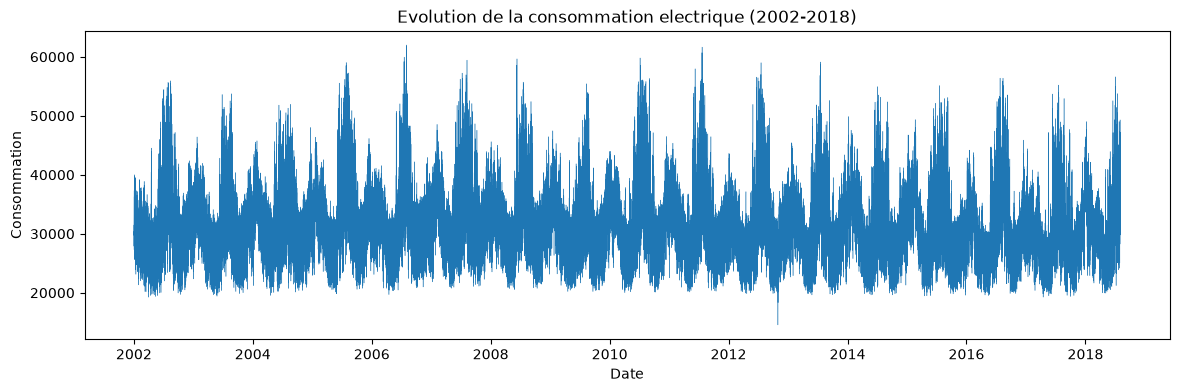

In [170]:
plt.figure(figsize=(14, 4))
plt.plot(s_interp, linewidth=0.3)
plt.title("Evolution de la consommation electrique (2002-2018)")
plt.xlabel("Date")
plt.ylabel("Consommation")

plt.show()

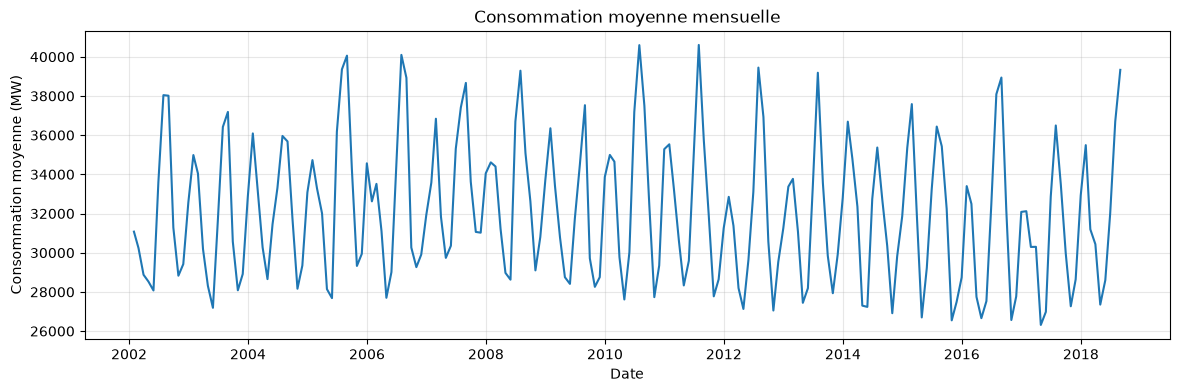

In [171]:
mensuelle = s_interp.resample("ME").mean()

plt.figure(figsize=(14, 4))
plt.plot(mensuelle)
plt.title("Consommation moyenne mensuelle")
plt.xlabel("Date")
plt.ylabel("Consommation moyenne (MW)")
plt.grid(alpha=0.3)
plt.show()

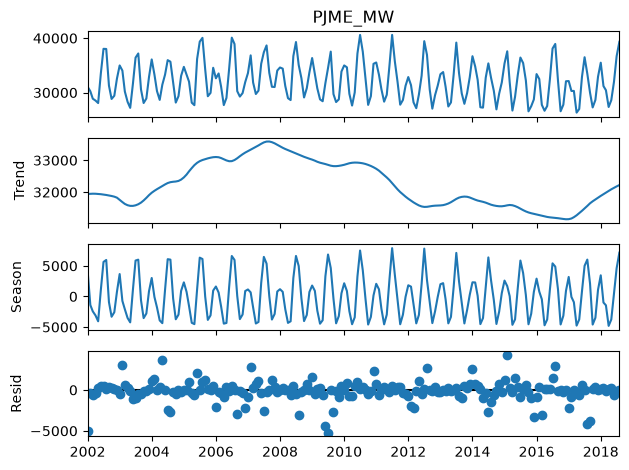

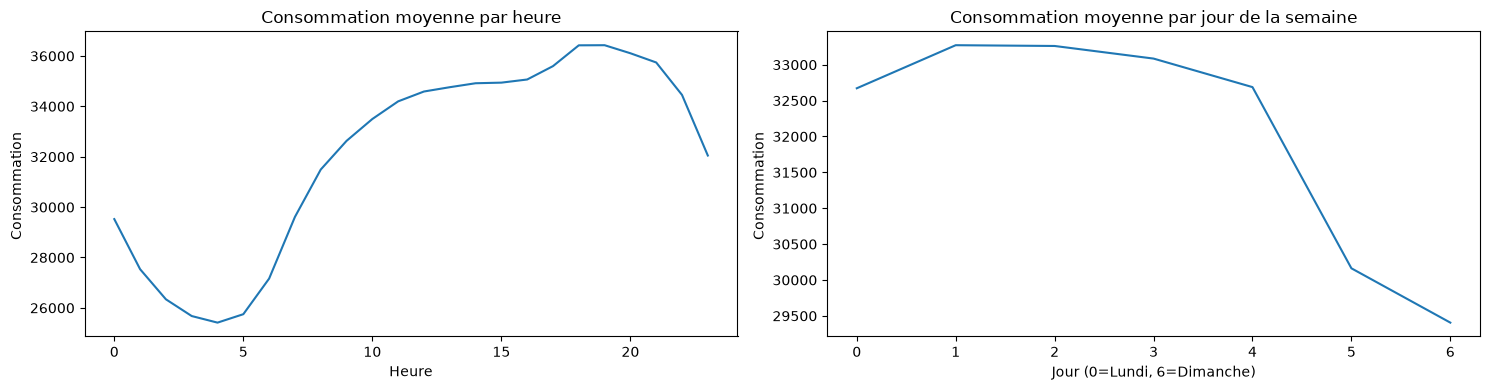

In [172]:
df_ts = s_interp.to_frame("PJME_MW").sort_index()

monthly = df_ts["PJME_MW"].resample("MS").mean()
result = STL(monthly, period=12, robust=True).fit()
result.plot()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

df_ts.groupby(df_ts.index.hour)["PJME_MW"].mean().plot(
    ax=axes[0], title="Consommation moyenne par heure")

df_ts.groupby(df_ts.index.dayofweek)["PJME_MW"].mean().plot(
    ax=axes[1], title="Consommation moyenne par jour de la semaine")

axes[0].set_xlabel("Heure")
axes[1].set_xlabel("Jour (0=Lundi, 6=Dimanche)")
axes[0].set_ylabel("Consommation ")
axes[1].set_ylabel("Consommation ")

plt.tight_layout()
plt.show()

### Observations

- **Tendance :** Hausse de la consommation entre 2003 et 2007, puis baisse jusqu'en 2017.
- **Saisonnalité annuelle :** Présence de fluctuations régulières chaque année.
- **Variation journalière :** Consommation minimale vers 4 h et maximale vers 18 h–19 h.
- **Variation hebdomadaire :** Consommation plus élevée en semaine et plus faible le week-end.

## Etape 4: feature enginering

### variables temporelles

In [173]:
df_ts["Hour"] = df_ts.index.hour
df_ts["DayOfWeek"] = df_ts.index.dayofweek
df_ts["Month"] = df_ts.index.month
df_ts["Year"] = df_ts.index.year
df_ts["IsWeekend"] = (df_ts["DayOfWeek"] >= 5).astype(int)

df_ts.head()

,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend
Datetime,,,,,,
2002-01-01 01:00:00,30393.0,1,1,1,2002,0
2002-01-01 02:00:00,29265.0,2,1,1,2002,0
2002-01-01 03:00:00,28357.0,3,1,1,2002,0
2002-01-01 04:00:00,27899.0,4,1,1,2002,0
2002-01-01 05:00:00,28057.0,5,1,1,2002,0


### variables de retard 

In [174]:
df_ts["lag_24"] = df_ts["PJME_MW"].shift(24)
df_ts["lag_168"] = df_ts["PJME_MW"].shift(168)

df_ts[["PJME_MW", "lag_24", "lag_168"]].head()

,PJME_MW,lag_24,lag_168
Datetime,,,
2002-01-01 01:00:00,30393.0,NaN,NaN
2002-01-01 02:00:00,29265.0,NaN,NaN
2002-01-01 03:00:00,28357.0,NaN,NaN
2002-01-01 04:00:00,27899.0,NaN,NaN
2002-01-01 05:00:00,28057.0,NaN,NaN


### 24 heures rooling average

In [175]:
df_ts["roll_24"]=df_ts["PJME_MW"].shift(1).rolling(24).mean()

df_ts[["PJME_MW","roll_24"]].head(30)

,PJME_MW,roll_24
Datetime,,
2002-01-01 01:00:00,30393.0,NaN
2002-01-01 02:00:00,29265.0,NaN
2002-01-01 03:00:00,28357.0,NaN
2002-01-01 04:00:00,27899.0,NaN
2002-01-01 05:00:00,28057.0,NaN
2002-01-01 06:00:00,28654.0,NaN
2002-01-01 07:00:00,29308.0,NaN
2002-01-01 08:00:00,29595.0,NaN
2002-01-01 09:00:00,29943.0,NaN


### supprimer les rows  avec lag manquants

In [176]:
df_ts= df_ts.dropna()

print(df_ts.isna().sum())
print("dimensions:",df_ts.shape)

PJME_MW      0
Hour         0
DayOfWeek    0
Month        0
Year         0
IsWeekend    0
lag_24       0
lag_168      0
roll_24      0
dtype: int64
dimensions: (145224, 9)


### Preparation les variables Categorials

In [177]:
df_model=pd.get_dummies(
    df_ts,columns=["Hour","DayOfWeek","Month"],drop_first=True,dtype=int)

df_model.head()

,PJME_MW,Year,IsWeekend,lag_24,lag_168,roll_24,Hour_1,Hour_2,Hour_3,Hour_4,...,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,Month_10,Month_11,Month_12
Datetime,,,,,,,,,,,,,,,,,,,,,
2002-01-08 01:00:00,29445.0,2002,0,26862.0,30393.0,33452.583333,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2002-01-08 02:00:00,28670.0,2002,0,25976.0,29265.0,33560.208333,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2002-01-08 03:00:00,28375.0,2002,0,25641.0,28357.0,33672.458333,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2002-01-08 04:00:00,28542.0,2002,0,25666.0,27899.0,33786.375000,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2002-01-08 05:00:00,29261.0,2002,0,26328.0,28057.0,33906.208333,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Preparation des donnes

definer cible et features

In [178]:
target="PJME_MW"
X=df_model.drop(columns=[target])
y=df_model[target]

print("features:",X.shape)
print("cible:",y.shape)

features: (145224, 45)
cible: (145224,)


### train test split

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["PJME_MW"])  
y = df["PJME_MW"]                 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

Train : (116179, 45)
Test : (29045, 45)
Train dates : 2002-01-08 01:00:00 2015-04-10 19:00:00
Test dates : 2015-04-10 20:00:00 2018-08-03 00:00:00


### Entrainement

In [180]:
model= LinearRegression()

model.fit(X_train,y_train)

y_pred=model.predict(X_test)

print(y_pred[:5])

[32501.4155493  32235.70514177 30873.44660274 28565.00810996
 24998.69773722]


## baseline model

In [181]:
y_baseline = X_test["lag_24"]

print(y_baseline.head())

Datetime
2015-04-10 20:00:00    33843.0
2015-04-10 21:00:00    33755.0
2015-04-10 22:00:00    32363.0
2015-04-10 23:00:00    30060.0
2015-04-11 00:00:00    27846.0
Freq: h, Name: lag_24, dtype: float64


### Evualtion des models

In [182]:
def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100
    }

results = pd.DataFrame({
    "Baseline lag_24": evaluate(y_test, y_baseline),
    "Linear Regression": evaluate(y_test, y_pred)
}).T

results.round(3)

,MAE,RMSE,R2,MAPE (%)
Baseline lag_24,2184.238,3009.006,0.785,6.931
Linear Regression,1675.914,2240.295,0.881,5.295


### Visualtion  actual vs predicted

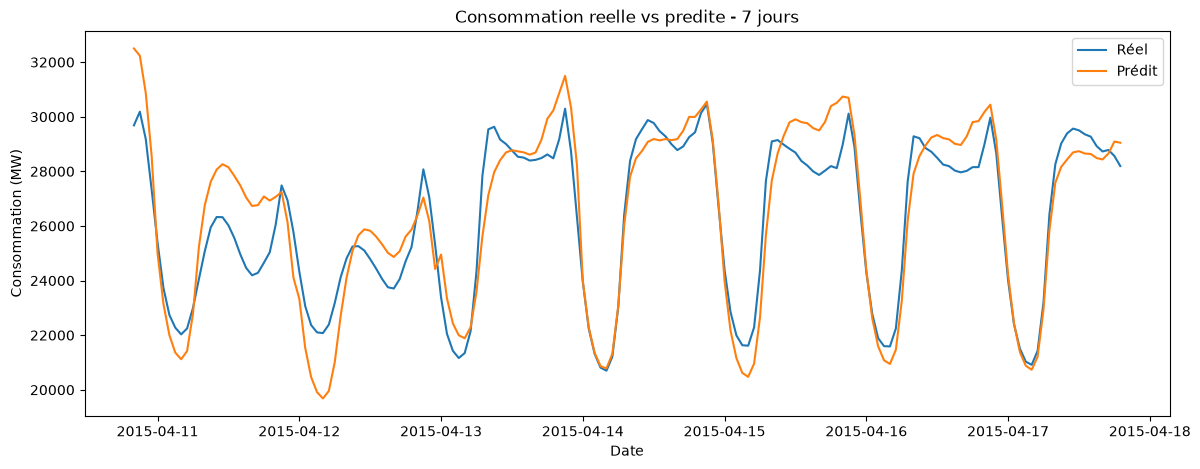

In [183]:
y_pred = pd.Series(y_pred, index=y_test.index)

plt.figure(figsize=(14, 5))

plt.plot(y_test.iloc[:168], label="Réel")
plt.plot(y_pred.iloc[:168], label="Prédit")

plt.title("Consommation reelle vs predite - 7 jours")
plt.xlabel("Date")
plt.ylabel("Consommation (MW)")
plt.legend()
plt.show()

### Analyse residuals

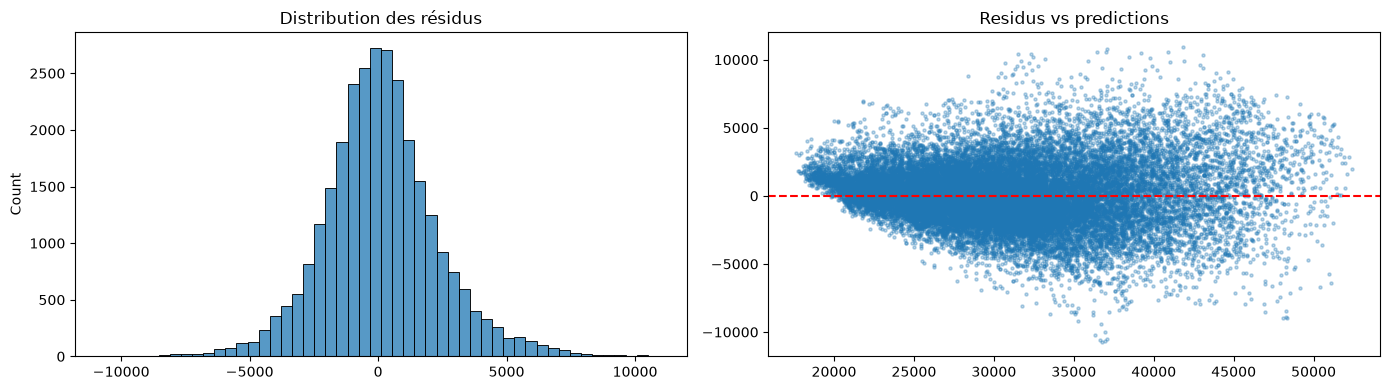

In [184]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(residuals, bins=50, ax=axes[0])
axes[0].set_title("Distribution des résidus")

axes[1].scatter(y_pred, residuals, alpha=0.3, s=5)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residus vs predictions")

plt.tight_layout()
plt.show()